# Entrega 4 — Modelagem e integração com o aplicativo
Bruno Henrique e Luiz Henrique

Este notebook complementa a análise da Entrega 2 (`notebook.ipynb`), que tratou a base e fez a análise exploratória, e executa o plano de modelagem da seção 6 daquele notebook.

**O que é estimado:** a quantidade registrada de homicídios de mulheres, por grande região, no ano seguinte. É uma **estimativa acadêmica agregada**. Ela não prevê risco individual e não identifica pessoas.

| Item | Decisão |
|---|---|
| Base | `dados/base_tratada.csv` (120 linhas: 5 regiões × 2000–2023), a mesma da Entrega 2 |
| Alvo | crescimento logarítmico anual `log(y_t / y_(t-1))` da contagem regional |
| Entradas | crescimento do ano anterior `log(y_(t-1) / y_(t-2))` e a região |
| Modelos | referência (repete o ano anterior) e regressão Ridge |
| Validação | validação cruzada com janela expansiva por ano (sem embaralhar) e teste final em 2020–2023 |
| Métricas | MAE, RMSE e MAPE, na unidade original (óbitos registrados) |

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
DADOS = Path('dados')
df = pd.read_csv(DADOS / 'base_tratada.csv', sep=';', decimal=',', encoding='utf-8-sig')
df = df.sort_values(['regiao', 'ano']).reset_index(drop=True)
print(df.shape, df['ano'].min(), df['ano'].max())
print(df['homicidios_mulheres'].isna().sum(), 'contagens ausentes')
df.head()

(120, 4) 2000 2023
0 contagens ausentes


,ano,regiao,homicidios_mulheres,taxa_por_100_mil_mulheres
0,2000,Centro-Oeste,336,5.69
1,2001,Centro-Oeste,331,5.49
2,2002,Centro-Oeste,364,5.91
3,2003,Centro-Oeste,359,5.71
4,2004,Centro-Oeste,348,5.43


## 1. Série por região
A contagem não tem valores ausentes (as cinco taxas ausentes de 2023 não entram, pois o modelo usa só a contagem). Os níveis das regiões são muito diferentes, por isso o modelo trabalha com o **crescimento relativo** de um ano para o outro, e não com o valor absoluto.

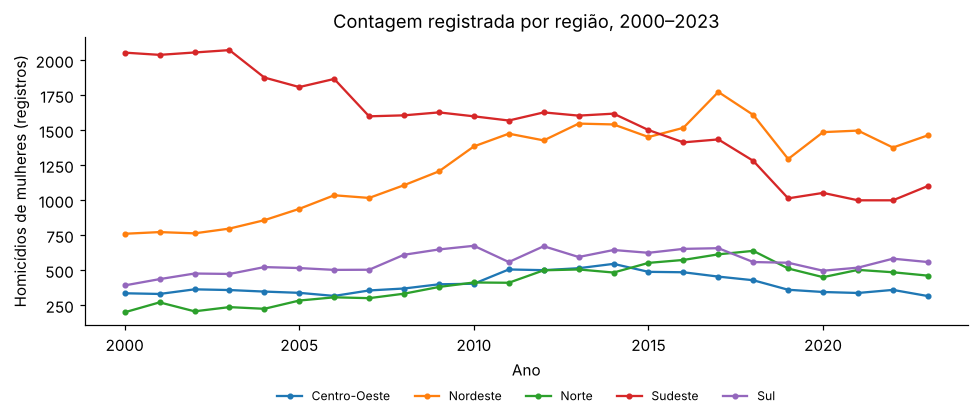

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
for regiao, g in df.groupby('regiao'):
    ax.plot(g['ano'], g['homicidios_mulheres'], marker='o', ms=3, label=regiao)
ax.set_xlabel('Ano')
ax.set_ylabel('Homicídios de mulheres (registros)')
ax.set_title('Contagem registrada por região, 2000–2023')
ax.legend(ncol=5, fontsize=8, loc='upper center', bbox_to_anchor=(0.5, -0.18), frameon=False)
plt.tight_layout()
plt.show()

## 2. Preparação das variáveis
Para cada região e ano `t` usamos apenas informação **anterior** a `t`: a contagem em `t-1` e `t-2`. Nenhum valor futuro entra nas entradas. Como cada linha precisa de dois anos anteriores, a primeira linha possível é 2002.

In [3]:
d = df.rename(columns={'homicidios_mulheres': 'y'}).copy()
g = d.groupby('regiao')['y']
d['lag1'] = g.shift(1)
d['lag2'] = g.shift(2)
d['momento'] = np.log(d['lag1'] / d['lag2'])
d['crescimento'] = np.log(d['y'] / d['lag1'])
base = d.dropna(subset=['lag1', 'lag2']).reset_index(drop=True)
print(len(base), 'linhas utilizáveis;', base['ano'].min(), 'a', base['ano'].max())
base[['regiao', 'ano', 'y', 'lag1', 'lag2', 'momento', 'crescimento']].head()

110 linhas utilizáveis; 2002 a 2023


,regiao,ano,y,lag1,lag2,momento,crescimento
0,Centro-Oeste,2002,364,331.0,336.0,-0.014993,0.095035
1,Centro-Oeste,2003,359,364.0,331.0,0.095035,-0.013831
2,Centro-Oeste,2004,348,359.0,364.0,-0.013831,-0.031120
3,Centro-Oeste,2005,339,348.0,359.0,-0.031120,-0.026202
4,Centro-Oeste,2006,317,339.0,348.0,-0.026202,-0.067098


## 3. Modelos e métricas
A **referência** estima que o ano seguinte repete o anterior (`crescimento = 0`). A **regressão Ridge** aprende o crescimento a partir do crescimento anterior e da região, com padronização feita dentro do pipeline (ajustada só no treino de cada fold). A previsão volta à unidade original por `y_estimado = y_(t-1) · exp(crescimento_estimado)`.

In [4]:
def metricas(y, yhat):
    erro = yhat - y
    return {'MAE': np.mean(np.abs(erro)), 'RMSE': np.sqrt(np.mean(erro ** 2)), 'MAPE (%)': np.mean(np.abs(erro) / y) * 100}

def criar_ridge(alpha):
    pre = ColumnTransformer([
        ('num', StandardScaler(), ['momento']),
        ('cat', OneHotEncoder(handle_unknown='ignore'), ['regiao']),
    ])
    return Pipeline([('pre', pre), ('modelo', Ridge(alpha=alpha))])

COLUNAS = ['momento', 'regiao']

def prever_referencia(treino, alvo):
    return alvo['lag1'].to_numpy()

def prever_ridge(alpha):
    def f(treino, alvo):
        m = criar_ridge(alpha).fit(treino[COLUNAS], treino['crescimento'])
        return alvo['lag1'].to_numpy() * np.exp(m.predict(alvo[COLUNAS]))
    return f

## 4. Validação cruzada temporal
Os anos de 2020 a 2023 ficam reservados para o teste final e **não participam** da escolha do modelo. Com os anos de 2002 a 2019 fazemos validação cruzada de janela expansiva: em cada fold, treina-se com todos os anos anteriores ao bloco e valida-se em um bloco de dois anos. Os anos nunca são embaralhados.

In [5]:
ANO_TESTE = 2020
treino_total = base[base['ano'] < ANO_TESTE]
teste = base[base['ano'] >= ANO_TESTE]
folds = [(2012, 2013), (2014, 2015), (2016, 2017), (2018, 2019)]
candidatos = {'Referência (repete o ano anterior)': prever_referencia}
for a in [0.1, 1, 3, 10, 30]:
    candidatos[f'Ridge (alpha={a})'] = prever_ridge(a)

linhas = []
for nome, prever in candidatos.items():
    for i, (ini, fim) in enumerate(folds, 1):
        tr = treino_total[treino_total['ano'] < ini]
        va = treino_total[treino_total['ano'].between(ini, fim)]
        m = metricas(va['y'].to_numpy(), prever(tr, va))
        linhas.append({'modelo': nome, 'fold': i, 'validação': f'{ini}–{fim}', 'treino até': ini - 1, **m})
cv = pd.DataFrame(linhas)
resumo_cv = cv.groupby('modelo', sort=False)[['MAE', 'RMSE', 'MAPE (%)']].agg(['mean', 'std']).round(2)
resumo_cv

MAE           RMSE        MAPE (%)      
                                     mean    std    mean    std     mean   std
modelo                                                                        
Referência (repete o ano anterior)  70.92  36.18   94.27  45.18     8.08  4.35
Ridge (alpha=0.1)                   80.28  50.84  107.82  66.21     9.07  6.62
Ridge (alpha=1)                     79.13  51.40  106.50  66.49     8.99  6.62
Ridge (alpha=3)                     77.16  52.40  104.69  66.68     8.84  6.62
Ridge (alpha=10)                    75.56  52.72  103.02  65.55     8.70  6.53
Ridge (alpha=30)                    77.55  50.50  103.44  62.27     8.83  6.23

In [6]:
cv.pivot(index='modelo', columns='validação', values='MAE').loc[list(candidatos)].round(1)

validação,2012–2013,2014–2015,2016–2017,2018–2019
modelo,,,,
Referência (repete o ano anterior),55.3,47.6,55.9,124.9
Ridge (alpha=0.1),52.7,61.4,50.7,156.2
Ridge (alpha=1),49.5,60.6,50.5,155.9
Ridge (alpha=3),44.2,59.1,50.1,155.2
Ridge (alpha=10),41.3,56.6,50.3,154.1
Ridge (alpha=30),45.5,60.6,51.4,152.7


A tabela acima mostra o MAE de cada fold. A regra de escolha foi definida antes do teste final: vence o candidato de **menor MAE médio na validação cruzada**, incluindo a referência. O teste final não participa dessa decisão.

In [7]:
REFERENCIA = 'Referência (repete o ano anterior)'
medias = cv.groupby('modelo')['MAE'].mean()
melhor_ridge = medias.drop(REFERENCIA).idxmin()
modelo_final = medias.idxmin()
print('Melhor Ridge na validação cruzada:', melhor_ridge, '| MAE médio =', round(medias[melhor_ridge], 2))
print('Referência | MAE médio =', round(medias[REFERENCIA], 2))
print('Modelo escolhido pela regra da validação cruzada:', modelo_final)

Melhor Ridge na validação cruzada: Ridge (alpha=10) | MAE médio = 75.56
Referência | MAE médio = 70.92
Modelo escolhido pela regra da validação cruzada: Referência (repete o ano anterior)


## 5. Avaliação final no teste (2020–2023)
O modelo escolhido e a referência são ajustados com todos os anos até 2019 e avaliados nos anos reservados.

In [8]:
y_teste = teste['y'].to_numpy()
previsto = {
    'Referência': prever_referencia(treino_total, teste),
    'Ridge': candidatos[melhor_ridge](treino_total, teste),
}
tabela_teste = pd.DataFrame({k: metricas(y_teste, v) for k, v in previsto.items()}).T.round(2)
tabela_teste

,MAE,RMSE,MAPE (%)
Referência,50.8,68.00,6.86
Ridge,46.7,63.08,6.98


In [9]:
teste_det = teste[['regiao', 'ano', 'y']].copy()
teste_det['ref'] = previsto['Referência']
teste_det['ridge'] = previsto['Ridge']
por_regiao = teste_det.groupby('regiao').apply(
    lambda t: pd.Series({
        'MAE referência': np.mean(np.abs(t['ref'] - t['y'])),
        'MAE Ridge': np.mean(np.abs(t['ridge'] - t['y'])),
    }),
    include_groups=False,
).round(1)
por_regiao

,MAE referência,MAE Ridge
regiao,,
Centro-Oeste,22.2,26.1
Nordeste,102.8,74.8
Norte,38.8,48.8
Sudeste,48.5,45.8
Sul,41.8,38.1


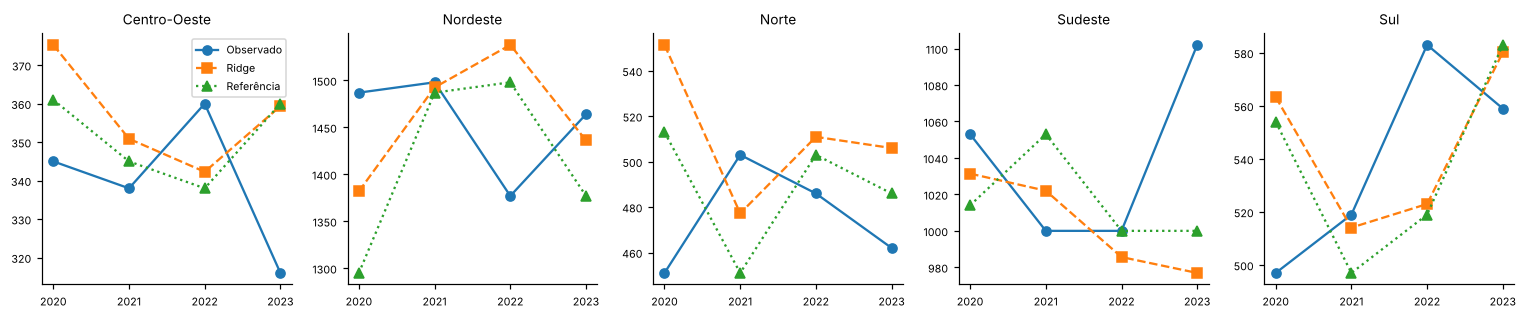

In [10]:
fig, eixos = plt.subplots(1, 5, figsize=(14, 3), sharex=True)
for ax, (regiao, t) in zip(eixos, teste_det.groupby('regiao')):
    ax.plot(t['ano'], t['y'], marker='o', label='Observado')
    ax.plot(t['ano'], t['ridge'], marker='s', ls='--', label='Ridge')
    ax.plot(t['ano'], t['ref'], marker='^', ls=':', label='Referência')
    ax.set_title(regiao, fontsize=9)
    ax.set_xticks(sorted(teste['ano'].unique()))
    ax.tick_params(labelsize=7)
eixos[0].legend(fontsize=7)
plt.tight_layout()
plt.show()

In [11]:
print(f"MAE no teste — referência: {tabela_teste.loc['Referência', 'MAE']:.1f} | Ridge: {tabela_teste.loc['Ridge', 'MAE']:.1f}")
print('Modelo usado na estimativa para o aplicativo (escolhido na validação cruzada):', modelo_final)

MAE no teste — referência: 50.8 | Ridge: 46.7
Modelo usado na estimativa para o aplicativo (escolhido na validação cruzada): Referência (repete o ano anterior)


**Leitura honesta do resultado.** Na validação cruzada a referência teve MAE médio menor que qualquer Ridge testado. No teste final, o Ridge ficou com MAE um pouco menor, mas com MAPE igual ou pior, e a diferença é pequena diante da variação entre regiões e entre folds (20 observações de teste e desvio-padrão alto nos folds). Esse conjunto não permite afirmar que a regressão supera a referência. Seguindo a regra definida antes do teste, o aplicativo usa a estimativa mais simples (o valor do último ano) e informa o erro típico (MAE) da validação cruzada. A conclusão é um resultado legítimo: com só o histórico de contagens regionais, há pouca informação além do último valor.

## 6. Integração com o aplicativo
Depois da validação, o modelo escolhido pela regra da validação cruzada é aplicado aos dados de **todos** os anos disponíveis (se fosse o Ridge, seria reajustado com 2002–2023) para estimar 2024 em cada região. O resultado é gravado em `indicadores_regionais.json` e carregado pela API na tabela `indicadores`. O aplicativo lê `GET /indicadores` e mostra o valor na Área de Apoio, sempre com o aviso de estimativa acadêmica.

A margem exibida é o **MAE da validação cruzada** do modelo usado, calculado na própria região.

In [12]:
todos = base.copy()
ultimo = d[d['ano'] == d['ano'].max()].copy()
ultimo = ultimo.merge(d[d['ano'] == d['ano'].max() - 1][['regiao', 'y']].rename(columns={'y': 'y_ant'}), on='regiao')
alvo = pd.DataFrame({
    'regiao': ultimo['regiao'],
    'lag1': ultimo['y'].to_numpy(),
    'momento': np.log(ultimo['y'] / ultimo['y_ant']).to_numpy(),
})

if modelo_final.startswith('Ridge'):
    alpha = float(modelo_final.split('=')[1].rstrip(')'))
    final = criar_ridge(alpha).fit(todos[COLUNAS], todos['crescimento'])
    estimado = alvo['lag1'].to_numpy() * np.exp(final.predict(alvo[COLUNAS]))
else:
    estimado = alvo['lag1'].to_numpy()
nome_modelo = modelo_final
chave_cv = modelo_final

mae_regiao_cv = {}
for regiao in sorted(base['regiao'].unique()):
    erros = []
    for ini, fim in folds:
        tr = treino_total[treino_total['ano'] < ini]
        va = treino_total[(treino_total['ano'].between(ini, fim)) & (treino_total['regiao'] == regiao)]
        erros.extend(np.abs(candidatos[chave_cv](tr, va) - va['y'].to_numpy()))
    mae_regiao_cv[regiao] = float(np.mean(erros))

ano_obs = int(d['ano'].max())
saida = pd.DataFrame({
    'regiao': alvo['regiao'],
    'anoObservado': ano_obs,
    'observado': alvo['lag1'].astype(int),
    'anoEstimado': ano_obs + 1,
    'estimado': np.round(estimado).astype(int),
    'margem': [int(round(mae_regiao_cv[r])) for r in alvo['regiao']],
    'modelo': nome_modelo,
}).sort_values('regiao').reset_index(drop=True)
saida

,regiao,anoObservado,observado,anoEstimado,estimado,margem,modelo
0,Centro-Oeste,2023,316,2024,316,29,Referência (repete o ano anterior)
1,Nordeste,2023,1464,2024,1464,133,Referência (repete o ano anterior)
2,Norte,2023,462,2024,462,50,Referência (repete o ano anterior)
3,Sudeste,2023,1102,2024,1102,93,Referência (repete o ano anterior)
4,Sul,2023,559,2024,559,50,Referência (repete o ano anterior)


In [13]:
registros = saida.to_dict(orient='records')
destinos = [DADOS / 'indicadores_regionais.json']
api = Path('..') / '..' / 'api' / 'dados'
if api.exists():
    destinos.append(api / 'indicadores.json')
for destino in destinos:
    destino.write_text(json.dumps(registros, ensure_ascii=False, indent=2), encoding='utf-8')
    print('gravado:', destino)

gravado: dados/indicadores_regionais.json
gravado: ../../api/dados/indicadores.json


## 7. Conferência do que foi e do que não foi feito
- A validação respeitou a ordem temporal: nenhuma entrada usa valores do ano estimado ou posteriores e o teste (2020–2023) não participou da escolha do modelo.
- As métricas (MAE, RMSE, MAPE) estão na unidade original. A escolha do modelo seguiu a validação cruzada; o teste final serviu apenas para conferência.
- O resultado é uma **estimativa acadêmica agregada por região**. Não permite concluir sobre o risco de uma pessoa, não explica causas e não equivale a casos classificados como feminicídio.
- Limitações: poucos anos, sub-registro, revisões nos registros e mudanças de classificação ao longo do tempo; o ano estimado (2024) não pode ser conferido com a base atual.